# ПР9 системы ИИ

## 1. Загрузка данных

Загружу готовый набор данных о признаках опухолей. Проверю количество классов, чтобы определить тип классификации.

In [3]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print("Количество объектов:", X.shape[0])
print("Количество признаков:", X.shape[1])
print("Классы:", list(enumerate(data.target_names)))
print("Количество классов:", y.nunique())
X.head()

Количество объектов: 569
Количество признаков: 30
Классы: [(0, np.str_('malignant')), (1, np.str_('benign'))]
Количество классов: 2


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Вывод:** классов два: 0 — злокачественная опухоль, 1 — доброкачественная. Значит, это бинарная классификация.

## 2. Разделение на обучающую и тестовую выборки

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Обучающая выборка:", len(X_train))
print("Тестовая выборка:", len(X_test))

Обучающая выборка: 455
Тестовая выборка: 114


## 3. Стандартизация признаков

У признаков разные масштабы значений. StandardScaler приводит их к сопоставимому масштабу.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Стандартизация выполнена")

Стандартизация выполнена


## 4. Обучение модели и прогноз

In [6]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

probabilities = model.predict_proba(X_test_scaled)
predictions = model.predict(X_test_scaled)

pd.DataFrame({
    "Вероятность класса 0": probabilities[:5, 0].round(3),
    "Вероятность класса 1": probabilities[:5, 1].round(3),
    "Прогноз": predictions[:5],
    "Настоящий класс": y_test.iloc[:5].to_numpy()
})

,Вероятность класса 0,Вероятность класса 1,Прогноз,Настоящий класс
0,1.000,0.000,0,0
1,0.000,1.000,1,1
2,0.994,0.006,0,0
3,0.466,0.534,1,1
4,1.000,0.000,0,0


## 5. Матрица ошибок и метрики

Матрица ошибок показывает, сколько ответов модель определила верно и неверно. По метрикам Accuracy, Precision, Recall и F1-score оценю качество классификации. Precision, Recall и F1-score считаются для класса 1.

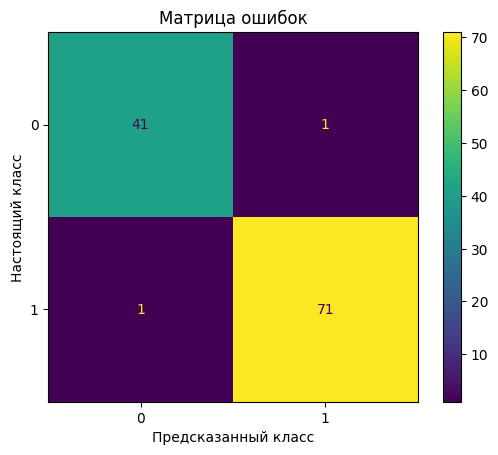

Accuracy: 0.982
Precision: 0.986
Recall: 0.986
F1-score: 0.986


In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, precision_score,
    recall_score, f1_score
)

ConfusionMatrixDisplay.from_predictions(y_test, predictions)
plt.title("Матрица ошибок")
plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")
plt.show()

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("Precision:", round(precision_score(y_test, predictions), 3))
print("Recall:", round(recall_score(y_test, predictions), 3))
print("F1-score:", round(f1_score(y_test, predictions), 3))


### Метрики качества модели

Обозначения:
- **TP = 71** — правильно определённые объекты класса 1.
- **TN = 41** — правильно определённые объекты класса 0.
- **FP = 1** — объекты класса 0, ошибочно отнесённые к классу 1.
- **FN = 1** — объекты класса 1, ошибочно отнесённые к классу 0.

Для оценки модели используются четыре метрики:

**1. Accuracy — общая точность.** Показывает долю правильных прогнозов среди всех объектов.

$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

$$
Accuracy = \frac{71 + 41}{71 + 41 + 1 + 1} = \frac{112}{114} \approx 0.982
$$

**2. Precision — точность положительных прогнозов.** Показывает, сколько объектов, отнесённых к положительному классу, действительно к нему относятся.

**Precision — сколько правильного среди найденного.**

$$
Precision = \frac{TP}{TP + FP}
$$

$$
Precision = \frac{71}{71 + 1} = \frac{71}{72} \approx 0.986
$$

**3. Recall — полнота.** Показывает, какую долю объектов положительного класса модель правильно обнаружила.

**Recall — сколько найдено среди всего правильного.**

$$
Recall = \frac{TP}{TP + FN}
$$

$$
Recall = \frac{71}{71 + 1} = \frac{71}{72} \approx 0.986
$$

**4. F1-score — баланс между Precision и Recall.**

$$
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

$$
F1 = 2 \cdot \frac{0.986 \cdot 0.986}{0.986 + 0.986}
\approx 0.986
$$




Разница между Precision и Recall:
- Precision — из всех объектов, которые модель назвала доброкачественными, сколько действительно доброкачественные?
- Recall — из всех действительно доброкачественных опухолей сколько модель смогла найти?



## 6. ROC-кривая и AUC-ROC

ROC-кривая показывает качество разделения двух классов при разных порогах. Чем ближе AUC к 1, тем лучше модель различает классы.

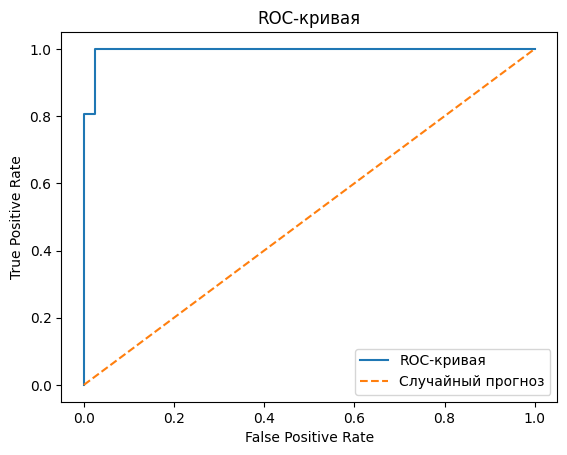

AUC-ROC: 0.995


In [8]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, probabilities[:, 1])
auc = roc_auc_score(y_test, probabilities[:, 1])

plt.plot(fpr, tpr, label="ROC-кривая")
plt.plot([0, 1], [0, 1], "--", label="Случайный прогноз")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая")
plt.legend()
plt.show()

print("AUC-ROC:", round(auc, 3))

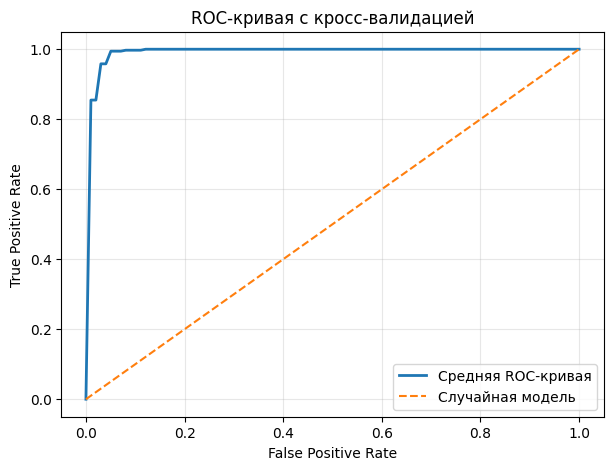

Средний AUC-ROC: 0.995
Стандартное отклонение AUC: 0.005


In [10]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

# Делим данные на 5 частей
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mean_fpr = np.linspace(0, 1, 100)
all_tpr = []
all_auc = []

# Обучаем и проверяем модель 5 раз
for train_idx, test_idx in cv.split(X, y):
    cv_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    cv_model.fit(X.iloc[train_idx], y.iloc[train_idx])

    probs = cv_model.predict_proba(X.iloc[test_idx])[:, 1]

    fpr, tpr, _ = roc_curve(y.iloc[test_idx], probs)

    # Приводим кривые к общим точкам
    tpr_interp = np.interp(mean_fpr, fpr, tpr)
    tpr_interp[0] = 0

    all_tpr.append(tpr_interp)
    all_auc.append(roc_auc_score(y.iloc[test_idx], probs))

# Усредняем результаты
mean_tpr = np.mean(all_tpr, axis=0)
mean_tpr[-1] = 1

# Строим график
plt.figure(figsize=(7, 5))
plt.plot(mean_fpr, mean_tpr, linewidth=2,
         label="Средняя ROC-кривая")
plt.plot([0, 1], [0, 1], "--", label="Случайная модель")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая с кросс-валидацией")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Средний AUC-ROC: {np.mean(all_auc):.3f}")
print(f"Стандартное отклонение AUC: {np.std(all_auc):.3f}")


## Дополнительное задание. Отбор признаков

Отбор признаков позволяет оставить только наиболее значимые признаки для модели.

У логистической регрессии каждому признаку соответствует вес. Чем больше вес по модулю, тем сильнее признак влияет на прогноз модели. Поскольку признаки стандартизированы, их веса можно сравнивать.

Выберем 10 признаков с наибольшими по модулю весами.

In [11]:
weights = pd.Series(abs(model.coef_[0]), index=X.columns)

top_features = weights.nlargest(10)

print("10 наиболее значимых признаков:")
display(top_features)


10 наиболее значимых признаков:


,0
worst texture,1.255088
radius error,1.082965
worst concave points,0.953686
worst area,0.947756
worst radius,0.947616
worst symmetry,0.939181
area error,0.929104
worst concavity,0.823151
worst perimeter,0.763220
worst smoothness,0.746625


Теперь обучим новую логистическую регрессию только на выбранных признаках и сравним точность с исходной моделью.

In [12]:
columns = [X.columns.get_loc(name) for name in top_features.index]

model_10 = LogisticRegression(max_iter=1000)
model_10.fit(X_train_scaled[:, columns], y_train)

# Делаем прогноз
predictions_10 = model_10.predict(X_test_scaled[:, columns])

# Сравниваем точность моделей
print("Accuracy на 30 признаках:",
      round(accuracy_score(y_test, predictions), 3))

print("Accuracy на 10 признаках:",
      round(accuracy_score(y_test, predictions_10), 3))


Accuracy на 30 признаках: 0.982
Accuracy на 10 признаках: 0.982


**Вывод:** Я выбрала 10 наиболее значимых признаков на основе весов логистической регрессии. После отбора точность модели не изменилась и составила 0.982. Количество признаков удалось сократить с 30 до 10 без потери точности на тестовой выборке.